# Outcome prediction: comparing models

Collects the val (2022) results that notebooks 01–11 saved to `results/`. Every model uses the same split, features, preprocessing and metrics. Each is evaluated with default hyperparameters and again after tuning.

**Macro-F1 is the main metric.** Accuracy is dominated by Adoption (about 60% of val), so the always-Adoption baseline already gets about 0.60 accuracy. The **Euthanasia (at-risk) recall** column shows whether a model can flag the animals that need attention.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parent))
import utils

LABELS = utils.OUTCOME_CLASSES
rows = [json.loads(p.read_text()) for p in sorted(Path("results").glob("*.json"))]
all_res = pd.DataFrame(rows).set_index("model")
untuned = all_res[~all_res.index.str.endswith("(tuned)")]
tuned = all_res[all_res.index.str.endswith("(tuned)")].rename(index=lambda s: s.replace(" (tuned)", ""))
base = untuned.loc["Majority class (baseline)"]

cols = ["accuracy", "macro_f1"]
table = pd.concat({"untuned": untuned[cols], "tuned": tuned[cols]}, axis=1)
table[("delta", "macro_f1")] = table[("tuned", "macro_f1")] - table[("untuned", "macro_f1")]
table[("tuned", "train_accuracy")] = tuned["train_accuracy"]
table[("tuned", "recall_at_risk")] = tuned["recall_Euthanasia"]
table[("tuned", "precision_at_risk")] = tuned["precision_Euthanasia"]
table = table.sort_values(("tuned", "macro_f1"), ascending=False, na_position="last")
table.style.format("{:.3f}", na_rep="—").background_gradient(
    cmap="Greens", subset=[("tuned", "macro_f1"), ("tuned", "recall_at_risk")])

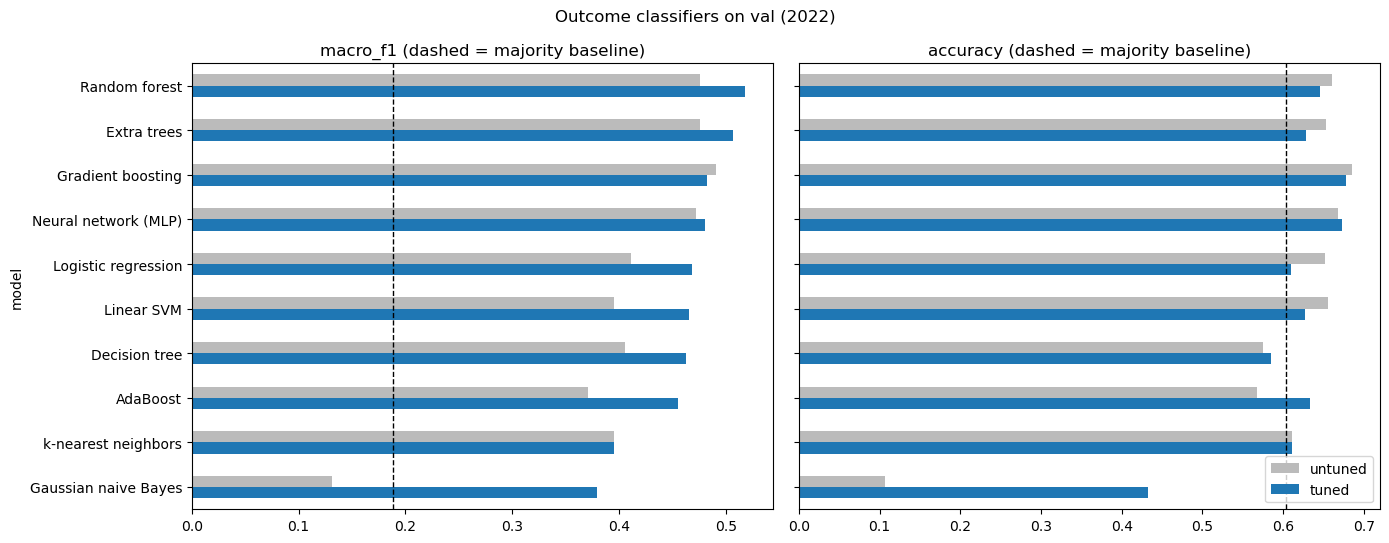

In [2]:
order = table.index.drop("Majority class (baseline)")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, m in zip(axes, ["macro_f1", "accuracy"]):
    pd.DataFrame({"untuned": untuned.loc[order, m], "tuned": tuned.loc[order, m]}).plot(
        kind="barh", ax=ax, color=["#bbbbbb", "C0"], legend=(m == "accuracy"))
    ax.axvline(base[m], color="k", ls="--", lw=1)
    ax.set_title(f"{m} (dashed = majority baseline)"); ax.invert_yaxis()
fig.suptitle("Outcome classifiers on val (2022)")
plt.tight_layout(); plt.savefig("results/model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

In [3]:
# Per-class recall after tuning: which outcomes can each model find?
rec = tuned.loc[order, [f"recall_{c}" for c in LABELS]]
rec.columns = LABELS
prec = tuned.loc[order, [f"precision_{c}" for c in LABELS]]
prec.columns = LABELS
display(rec.style.format("{:.2f}").background_gradient(cmap="Blues", axis=None).set_caption("Recall (tuned)"))
display(prec.style.format("{:.2f}").background_gradient(cmap="Oranges", axis=None).set_caption("Precision (tuned)"))

,Adoption,Transfer,Return to Owner,Euthanasia
model,,,,
Random forest,0.76,0.36,0.77,0.37
Extra trees,0.73,0.37,0.78,0.43
Gradient boosting,0.88,0.32,0.53,0.12
Neural network (MLP),0.89,0.33,0.40,0.16
Logistic regression,0.76,0.23,0.77,0.43
Linear SVM,0.80,0.23,0.71,0.36
Decision tree,0.67,0.32,0.81,0.53
AdaBoost,0.82,0.29,0.56,0.11
k-nearest neighbors,0.83,0.27,0.35,0.07


,Adoption,Transfer,Return to Owner,Euthanasia
model,,,,
Random forest,0.74,0.55,0.46,0.26
Extra trees,0.75,0.53,0.44,0.22
Gradient boosting,0.71,0.62,0.54,0.44
Neural network (MLP),0.70,0.61,0.53,0.53
Logistic regression,0.71,0.49,0.44,0.19
Linear SVM,0.71,0.57,0.46,0.16
Decision tree,0.75,0.52,0.39,0.14
AdaBoost,0.69,0.49,0.51,0.41
k-nearest neighbors,0.66,0.46,0.46,0.24


In [4]:
# Best hyperparameters found
tuned.loc[order, ["best_params", "tuning_minutes"]]

,best_params,tuning_minutes
model,,
Random forest,"{'n_estimators': 300, 'min_samples_leaf': 5, '...",2.802190
Extra trees,"{'n_estimators': 300, 'min_samples_leaf': 5, '...",4.274279
Gradient boosting,"{'class_weight': None, 'l2_regularization': 0....",8.649033
Neural network (MLP),"{'alpha': 0.0005342937261279777, 'batch_size':...",0.862714
Logistic regression,"{'C': 0.0019145111285710716, 'class_weight': '...",0.392465
Linear SVM,"{'C': 0.0054167545832474575, 'class_weight': '...",0.450929
Decision tree,"{'min_samples_leaf': 50, 'max_depth': 8, 'crit...",0.182960
AdaBoost,"{'estimator__max_depth': 3, 'learning_rate': 0...",6.121856
k-nearest neighbors,"{'weights': 'uniform', 'n_neighbors': 5}",0.483661


## Takeaways (val 2022)

| Model | Untuned acc / macro-F1 | Tuned acc / macro-F1 | Tuned at-risk recall / precision | Tuned train acc |
|---|---|---|---|---|
| **Random forest** | 0.661 / 0.475 | 0.646 / **0.518** | 0.37 / 0.26 | 0.794 |
| Extra trees | 0.653 / 0.476 | 0.628 / 0.507 | 0.43 / 0.22 | 0.798 |
| Gradient boosting | **0.686** / 0.490 | 0.678 / 0.482 | 0.12 / 0.44 | 0.771 |
| Neural network (MLP) | 0.668 / 0.472 | 0.673 / 0.480 | 0.16 / **0.53** | 0.707 |
| Logistic regression | 0.651 / 0.411 | 0.610 / 0.468 | 0.43 / 0.19 | 0.564 |
| Linear SVM | 0.656 / 0.395 | 0.627 / 0.465 | 0.36 / 0.16 | 0.608 |
| Decision tree | 0.575 / 0.406 | 0.586 / 0.463 | **0.53** / 0.14 | 0.599 |
| AdaBoost | 0.567 / 0.371 | 0.633 / 0.455 | 0.11 / 0.41 | 0.639 |
| k-nearest neighbors | 0.611 / 0.395 | 0.611 / 0.395 | 0.07 / 0.24 | 0.736 |
| Gaussian naive Bayes | 0.107 / 0.132 | 0.433 / 0.379 | 0.63 / 0.10 | 0.492 |
| *Majority baseline* | *0.604 / 0.188* | | | |

- **Best model: tuned random forest** (macro-F1 0.518, nearly 3× the baseline's 0.188). Its settings are class-balanced, 300 trees, depth 30, minimum 5 samples per leaf and 30% of features per split, the same as the best length-of-stay forest.
- **Outcome is much more predictable than length of stay:** macro-F1 0.52 vs. 0.41, and accuracy up to 0.69 vs. a 0.60 baseline. The outcome is largely set by intake facts (condition, age, owned stray vs. surrender).
- **There are two kinds of "good" model:**
  - **Balanced models** (random forest, extra trees, logistic regression, linear SVM) find 36–43% of at-risk animals but raise more false alarms (precision 0.16–0.26).
  - **Unweighted models** (gradient boosting, MLP, AdaBoost) are more accurate overall and more precise when they flag at-risk (0.41–0.53), but flag far fewer (11–16% recall).
  - For a "needs attention" screen, recall matters more, which favors the random forest. Notebook 13 shows the trade-off at different alert volumes.
- **Tuning helped most models,** mainly through class weighting. Gradient boosting got slightly worse (0.490 → 0.482): settings chosen on 2021 didn't carry over to 2022. For k-NN, the default k = 5 was already best.
- **Transfer is the hardest class** (recall 23–37%). Transfers depend on partner capacity and foster availability, which aren't in the data.